
# Week 6: Finalizing the Operations Model
## Random Forest Tuning for Late Delivery Prediction

This notebook continues the Operations Risk Layer work from Week 5. Random Forest was shortlisted as the strongest model, so the goal this week is to improve it through hyperparameter tuning and threshold calibration.

The corrected Version 2 files are used because the earlier 35-feature dataset included eight `Order Status` columns that could leak information about the delivery outcome. The corrected dataset contains 27 features.

The required input files are:

| File | Description |
|---|---|
| `operations_X_train_processed_v2.csv` | Corrected training features |
| `operations_X_test_processed_v2.csv` | Corrected test features |
| `operations_y_train_v2.csv` | Training target |
| `operations_y_test_v2.csv` | Test target |

The final comparison includes the corrected baseline model, the tuned model at the default threshold of 0.50 and the tuned model at the selected threshold.


## 1. Import the libraries

In [1]:

import os
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42



## 2. Load the corrected operations files

The code searches common Colab and local folders for the four Version 2 files. If they are not found in Colab, it asks for them to be uploaded.


In [2]:


REQUIRED_FILES = [
    "operations_X_train_processed_v2.csv",
    "operations_X_test_processed_v2.csv",
    "operations_y_train_v2.csv",
    "operations_y_test_v2.csv",
]

SEARCH_DIRS = [
    ".",
    "/content",
    "data",
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/CEROP",
]

DATA_DIR = next(
    (
        folder
        for folder in SEARCH_DIRS
        if all(os.path.exists(os.path.join(folder, name))
               for name in REQUIRED_FILES)
    ),
    None,
)

if DATA_DIR is None:
    try:
        from google.colab import files

        print("Upload the four Week 6 v2 CSV files.")
        files.upload()
        DATA_DIR = "."
    except ImportError:
        raise FileNotFoundError(
            "The four Week 6 v2 files were not found."
        )

# Load feature files
X_train = pd.read_csv(
    os.path.join(DATA_DIR, "operations_X_train_processed_v2.csv")
)

X_test = pd.read_csv(
    os.path.join(DATA_DIR, "operations_X_test_processed_v2.csv")
)

# Load target files
y_train_df = pd.read_csv(
    os.path.join(DATA_DIR, "operations_y_train_v2.csv")
)

y_test_df = pd.read_csv(
    os.path.join(DATA_DIR, "operations_y_test_v2.csv")
)

# Take the single target column directly
y_train = y_train_df.iloc[:, 0]
y_test = y_test_df.iloc[:, 0]

# Make sure targets are numeric integers
y_train = pd.to_numeric(y_train).astype(int)
y_test = pd.to_numeric(y_test).astype(int)

# Checks
assert X_train.shape[1] == 27, (
    f"Expected 27 corrected features, but found {X_train.shape[1]}."
)

assert X_test.shape[1] == 27, (
    f"Expected 27 corrected test features, but found {X_test.shape[1]}."
)

assert len(X_train) == len(y_train), (
    f"Training rows do not match: "
    f"X_train={len(X_train)}, y_train={len(y_train)}"
)

assert len(X_test) == len(y_test), (
    f"Test rows do not match: "
    f"X_test={len(X_test)}, y_test={len(y_test)}"
)

assert list(X_train.columns) == list(X_test.columns)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

print(
    "Late-delivery rate in training set:",
    round(y_train.mean(), 4)
)

print(
    "Late-delivery rate in test set:",
    round(y_test.mean(), 4)
)

Training features: (137569, 27)
Test features: (34393, 27)
Training target: (137569,)
Test target: (34393,)
Late-delivery rate in training set: 0.5482
Late-delivery rate in test set: 0.5482



## 3. Create a validation set

The test set is kept untouched while the model is tuned. A stratified validation set is separated from the training data and used only to choose the prediction threshold.


In [3]:

X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

print("Development set:", X_dev.shape)
print("Validation set:", X_val.shape)
print("Development late-delivery rate:", round(y_dev.mean(), 4))
print("Validation late-delivery rate:", round(y_val.mean(), 4))


Development set: (110055, 27)
Validation set: (27514, 27)
Development late-delivery rate: 0.5482
Validation late-delivery rate: 0.5482



## 4. Tune the Random Forest

`RandomizedSearchCV` tests 25 parameter combinations using stratified three-fold cross-validation and F1-score. Since the full training set is large, the search uses a stratified sample of up to 50,000 development rows. After the best settings are found, the selected model is trained again on the full development set.

This is a deliberate compute trade-off. It keeps the search practical while still allowing the final model to learn from all available development data.


In [4]:

SEARCH_SAMPLE_SIZE = 50_000

if len(X_dev) > SEARCH_SAMPLE_SIZE:
    X_search, _, y_search, _ = train_test_split(
        X_dev,
        y_dev,
        train_size=SEARCH_SAMPLE_SIZE,
        stratify=y_dev,
        random_state=RANDOM_STATE,
    )
else:
    X_search = X_dev.copy()
    y_search = y_dev.copy()

print("Rows used for hyperparameter search:", len(X_search))

param_dist = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
    param_distributions=param_dist,
    n_iter=25,
    scoring="f1",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=False,
)

search.fit(X_search, y_search)

print("Best cross-validation F1:", round(search.best_score_, 4))
print("Best parameters:")
for name, value in search.best_params_.items():
    print(f"  {name}: {value}")


Rows used for hyperparameter search: 50000
Fitting 3 folds for each of 25 candidates, totalling 75 fits


Best cross-validation F1: 0.7048
Best parameters:
  n_estimators: 500
  min_samples_split: 5
  min_samples_leaf: 1
  max_features: 0.5
  max_depth: None



## 5. Select the prediction threshold

Random Forest normally predicts a late delivery when its probability is at least 0.50. Week 5 showed that the baseline missed many late deliveries, so this section checks thresholds from 0.10 to 0.90 on the validation set.

The selected threshold is the one with the highest validation F1-score. Recall and precision are also shown because lowering the threshold usually catches more late deliveries but may produce more false alarms.


In [5]:

validation_model = RandomForestClassifier(
    **search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
validation_model.fit(X_dev, y_dev)

val_prob = validation_model.predict_proba(X_val)[:, 1]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.01):
    val_pred = (val_prob >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
    })

threshold_results = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_results.loc[
    threshold_results["F1"].idxmax()
]
BEST_THRESHOLD = float(best_threshold_row["Threshold"])

print("Selected threshold:", BEST_THRESHOLD)
print(best_threshold_row.round(4).to_string())

print("\nTop five thresholds by validation F1:")
print(
    threshold_results.sort_values("F1", ascending=False)
    .head(5)
    .round(4)
    .to_string(index=False)
)


Selected threshold: 0.4
Threshold    0.4000
Precision    0.6905
Recall       0.8171
F1           0.7485

Top five thresholds by validation F1:
 Threshold  Precision  Recall     F1
      0.40     0.6905  0.8171 0.7485
      0.39     0.6757  0.8382 0.7482
      0.38     0.6620  0.8587 0.7476
      0.41     0.7060  0.7940 0.7474
      0.37     0.6498  0.8791 0.7472


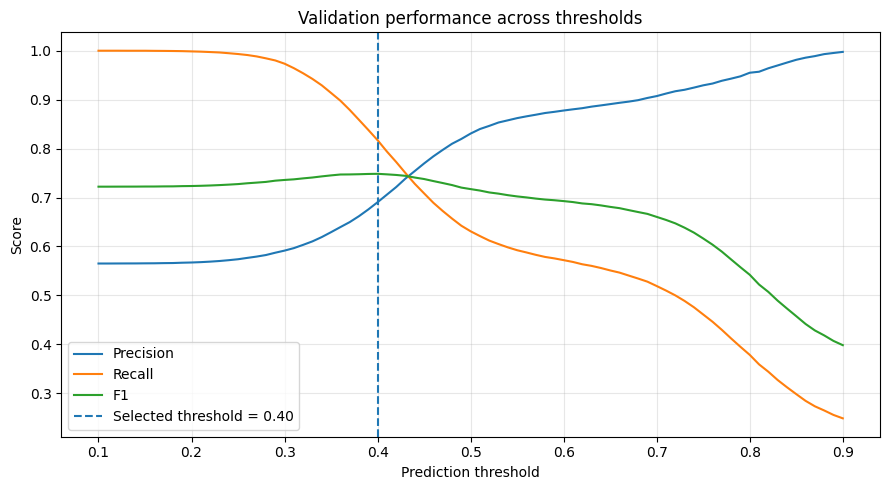

In [6]:

plt.figure(figsize=(9, 5))
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    label="Precision",
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    label="Recall",
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    label="F1",
)
plt.axvline(
    BEST_THRESHOLD,
    linestyle="--",
    label=f"Selected threshold = {BEST_THRESHOLD:.2f}",
)
plt.xlabel("Prediction threshold")
plt.ylabel("Score")
plt.title("Validation performance across thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 6. Train the final models and evaluate the test set

The corrected baseline and tuned Random Forest are now trained on the full training set. The test set is evaluated only in this final section.

Three results are reported:

1. Corrected baseline Random Forest at threshold 0.50  
2. Tuned Random Forest at threshold 0.50  
3. Tuned Random Forest at the selected validation threshold


In [7]:

baseline_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
baseline_model.fit(X_train, y_train)

final_model = RandomForestClassifier(
    **search.best_params_,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
final_model.fit(X_train, y_train)

baseline_prob = baseline_model.predict_proba(X_test)[:, 1]
tuned_prob = final_model.predict_proba(X_test)[:, 1]

def evaluate_predictions(model_name, threshold, probabilities):
    predictions = (probabilities >= threshold).astype(int)
    cm = confusion_matrix(y_test, predictions)
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
    }

    confusion_values = {
        "Model": model_name,
        "Threshold": threshold,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }

    return metrics, confusion_values

result_rows = []
confusion_rows = []

for name, threshold, probabilities in [
    ("Corrected Baseline RF", 0.50, baseline_prob),
    ("Tuned RF at 0.50", 0.50, tuned_prob),
    ("Tuned RF at Calibrated Threshold", BEST_THRESHOLD, tuned_prob),
]:
    metrics, cm_values = evaluate_predictions(
        name,
        threshold,
        probabilities,
    )
    result_rows.append(metrics)
    confusion_rows.append(cm_values)

tuning_results = pd.DataFrame(result_rows)
confusion_results = pd.DataFrame(confusion_rows)

print("FINAL TEST RESULTS")
print("=" * 110)
print(tuning_results.round(4).to_string(index=False))

print("\nCONFUSION MATRICES")
print("=" * 80)
print(confusion_results.to_string(index=False))


FINAL TEST RESULTS
                           Model  Threshold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
           Corrected Baseline RF        0.5    0.7303     0.8251  0.6446 0.7238   0.8141  0.8622
                Tuned RF at 0.50        0.5    0.7335     0.8452  0.6289 0.7212   0.8258  0.8730
Tuned RF at Calibrated Threshold        0.4    0.7191     0.7095  0.8254 0.7631   0.8258  0.8730

CONFUSION MATRICES
                           Model  Threshold    TN   FP   FN    TP
           Corrected Baseline RF        0.5 12963 2576 6701 12153
                Tuned RF at 0.50        0.5 13368 2171 6996 11858
Tuned RF at Calibrated Threshold        0.4  9168 6371 3291 15563



## 7. Compare the results

The table below calculates the change from the corrected baseline. This makes it easier to see whether tuning improved the model and how threshold calibration affected precision and recall.


In [8]:

baseline_values = tuning_results.iloc[0]

comparison = tuning_results.copy()
for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC",
]:
    comparison[f"{metric} Change"] = (
        comparison[metric] - baseline_values[metric]
    )

print(comparison.round(4).to_string(index=False))


                           Model  Threshold  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Accuracy Change  Precision Change  Recall Change  F1 Change  ROC-AUC Change  PR-AUC Change
           Corrected Baseline RF        0.5    0.7303     0.8251  0.6446 0.7238   0.8141  0.8622           0.0000            0.0000         0.0000     0.0000          0.0000         0.0000
                Tuned RF at 0.50        0.5    0.7335     0.8452  0.6289 0.7212   0.8258  0.8730           0.0032            0.0201        -0.0156    -0.0025          0.0117         0.0107
Tuned RF at Calibrated Threshold        0.4    0.7191     0.7095  0.8254 0.7631   0.8258  0.8730          -0.0112           -0.1156         0.1809     0.0394          0.0117         0.0107



## 8. Tuning result paragraph

The following cell creates a short paragraph using the actual results. It can be included in the group report with minor wording changes if needed.


In [9]:

baseline = tuning_results.iloc[0]
tuned_default = tuning_results.iloc[1]
tuned_calibrated = tuning_results.iloc[2]

if tuned_default["F1"] > baseline["F1"]:
    tuning_direction = "improved"
else:
    tuning_direction = "did not improve"

if tuned_calibrated["Recall"] > tuned_default["Recall"]:
    threshold_effect = (
        "The calibrated threshold increased recall, meaning the model caught "
        "more late deliveries, although this came with a change in precision."
    )
else:
    threshold_effect = (
        "The calibrated threshold did not increase recall compared with the "
        "default threshold."
    )

result_paragraph = (
    f"RandomizedSearchCV {tuning_direction} the Random Forest's test F1-score "
    f"from {baseline['F1']:.4f} for the corrected baseline to "
    f"{tuned_default['F1']:.4f} at the default threshold. "
    f"The tuned model produced a ROC-AUC of {tuned_default['ROC-AUC']:.4f} "
    f"and a PR-AUC of {tuned_default['PR-AUC']:.4f}. "
    f"{threshold_effect} At the selected threshold of "
    f"{BEST_THRESHOLD:.2f}, recall was {tuned_calibrated['Recall']:.4f}, "
    f"precision was {tuned_calibrated['Precision']:.4f} and F1-score was "
    f"{tuned_calibrated['F1']:.4f}."
)

print(result_paragraph)


RandomizedSearchCV did not improve the Random Forest's test F1-score from 0.7238 for the corrected baseline to 0.7212 at the default threshold. The tuned model produced a ROC-AUC of 0.8258 and a PR-AUC of 0.8730. The calibrated threshold increased recall, meaning the model caught more late deliveries, although this came with a change in precision. At the selected threshold of 0.40, recall was 0.8254, precision was 0.7095 and F1-score was 0.7631.


## 9. Save the Week 6 deliverables

In [10]:

best_params_df = pd.DataFrame([
    {
        "Best CV F1": search.best_score_,
        "Search Rows": len(X_search),
        "CV Folds": 3,
        "Search Iterations": 25,
        "Selected Threshold": BEST_THRESHOLD,
        **search.best_params_,
    }
])

tuning_results.to_csv(
    "week6_operations_tuning_results.csv",
    index=False,
)
confusion_results.to_csv(
    "week6_operations_confusion_matrices.csv",
    index=False,
)
best_params_df.to_csv(
    "week6_operations_best_params.csv",
    index=False,
)
threshold_results.to_csv(
    "week6_operations_threshold_results.csv",
    index=False,
)

with open(
    "week6_operations_tuning_summary.txt",
    "w",
    encoding="utf-8",
) as file:
    file.write(result_paragraph)

print("Saved: week6_operations_tuning_results.csv")
print("Saved: week6_operations_confusion_matrices.csv")
print("Saved: week6_operations_best_params.csv")
print("Saved: week6_operations_threshold_results.csv")
print("Saved: week6_operations_tuning_summary.txt")


Saved: week6_operations_tuning_results.csv
Saved: week6_operations_confusion_matrices.csv
Saved: week6_operations_best_params.csv
Saved: week6_operations_threshold_results.csv
Saved: week6_operations_tuning_summary.txt


In [11]:

result_files = [
    "week6_operations_tuning_results.csv",
    "week6_operations_confusion_matrices.csv",
    "week6_operations_best_params.csv",
    "week6_operations_threshold_results.csv",
    "week6_operations_tuning_summary.txt",
]

zip_name = "week6_operations_results.zip"

with zipfile.ZipFile(
    zip_name,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as zip_file:
    for file_name in result_files:
        if os.path.exists(file_name):
            zip_file.write(file_name)

print(f"Created: {zip_name}")

try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    print("The ZIP file is available in the current working folder.")


Created: week6_operations_results.zip
The ZIP file is available in the current working folder.


In [12]:
import joblib, os
out_dir = r"<AIT506_PROJECT_FOLDER>\CEROP_Live_Demo\models"
os.makedirs(out_dir, exist_ok=True)
joblib.dump(final_model, os.path.join(out_dir, "cerop_operations_rf.pkl"))
print("Saved cerop_operations_rf.pkl:", final_model)

Saved cerop_operations_rf.pkl: RandomForestClassifier(max_features=0.5, min_samples_split=5, n_estimators=500,
                       n_jobs=-1, random_state=42)
